# TP1 · Task 3: Individual and ensemble prediction models
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 3 asks three things: which kinds of information contribute to the prediction (an ablation by feature group), how individual
classifiers of different modelling principles perform, and whether ensembles improve on them. Everything runs under the evaluation
protocol that we fixed in Task 2 (`prepared/task2_protocol.json`): the same four expanding-window folds, the same metrics and the
same baselines. The final test period is not loaded, and no decision threshold is chosen here.

### How to read this notebook

| # | Section | Requirement of the Task 3 brief |
|---|---------|---------------------------------|
| 1 | Setup | — |
| 2 | Data, folds and baselines from Task 2 | the protocol that every result below follows |
| 3 | Feature-group ablation | four nested feature sets; tariff against time of day, post history, user history, consistency over time, operational and ethical concerns |
| 4 | Individual models | classifiers of at least three modelling principles, justified by data types, imbalance, assumptions, interpretability and cost |
| 5 | Ensemble models | at least three ensemble principles, with a leakage-free stacking |
| 6 | Comparison and conclusions | all models against the baselines, fold by fold |
| 7 | Saved files and decision log | — |

Two rules apply to every experiment. First, anything that learns from data (imputation values, caps, scaling, encoders, bins,
hyperparameters, the meta-model of a stacking) is fitted on the training rows of a fold and applied unchanged to its validation
quarter. Second, choices are made with the rule of Task 2 (Section 8): the unweighted mean PR-AUC over the four folds, read together
with the paired differences fold by fold.

---
## 1. Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, KBinsDiscretizer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler)
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task3"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

# Everything below that defines the evaluation comes from the Task 2 files, so the two tasks cannot drift apart.
PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
GROUPS = FEATURE_GROUPS["groups"]

# A difference in PR-AUC smaller than this is treated as a tie. It is about one bootstrap standard error of the PR-AUC of one
# validation fold (checked in Section 3.3), so it is the size of the noise and not a tuned value.
TOLERANCE = 0.005

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 7)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

---
## 2. Data, folds and baselines from Task 2

We load only the columns of the 29 eligible features and the three columns that define the target and the fold boundaries
(`Start Time`, `End Time`, `end_cause`). As in Task 2, the burn-in and the test rows are removed and only counted right after loading, so
the test sessions are not in memory for the rest of the notebook.

In [2]:
RENAME = {   # same short names as in Task 1 and Task 2
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}     # features built from one column (Task 1, Section 12)

features_all = [f for group in GROUPS.values() for f in group]
needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in features_all} | {"Start Time", "End Time", "end_cause"}
df = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
for col in ("location", "district", "tariff_period", "end_cause"):
    df[col] = df[col].str.strip()
for col in ("start_time", "end_time"):
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d %H:%M:%S")
df["hour"] = df["start_time"].dt.hour.astype("int8")
df["dow"] = df["start_time"].dt.dayofweek.astype("int8")
df["rain_flag"] = (df["precipitation"] > 0).astype("int8")
df[TARGET] = (~df["end_cause"].isin(NORMAL_CAUSES)).astype("int8")

n_total = len(df)
n_burn_in = int((df["start_time"] < BURN_IN_END).sum())
n_test = int((df["start_time"] >= TEST_START).sum())
df = df[(df["start_time"] >= BURN_IN_END) & (df["start_time"] < TEST_START)].reset_index(drop=True)   # the test rows disappear here

print(f"File: {n_total:,} sessions | burn-in removed: {n_burn_in:,} | test removed: {n_test:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), "
      f"abnormal share {df[TARGET].mean():.2%}")
print(f"Features available: {len(features_all)} in {len(GROUPS)} groups")
assert df["start_time"].max() < TEST_START and len(features_all) == 29

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%
Features available: 29 in 7 groups


### 2.1 The four temporal folds

The folds are rebuilt from the boundaries stored in the Task 2 protocol, with the same purge rule and the same assertions. Fold *k* trains on
every labelled development session that started and ended before its validation quarter, and validates on that quarter.

In [3]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"] and np.isin(a["train"], b["train"]).all()
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]      # same folds as Task 2
assert FOLDS[-1]["hi"] == TEST_START
print("The four folds match the Task 2 protocol and pass the temporal integrity checks.")

fold_table = pd.DataFrame([{"fold": f["fold"], "validation quarter": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
                            "train sessions": len(f["train"]), "validation sessions": len(f["valid"]),
                            "validation abnormal share": df.loc[f["valid"], TARGET].mean()} for f in FOLDS]).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal share": "{:.1%}"}))

The four folds match the Task 2 protocol and pass the temporal integrity checks.


,validation quarter,train sessions,validation sessions,validation abnormal share
fold,,,,
1,2020-10-01 to 2020-12-31,"111,470","60,364",16.8%
2,2021-01-01 to 2021-03-31,"171,832","41,797",15.8%
3,2021-04-01 to 2021-06-30,"213,641","57,542",18.2%
4,2021-07-01 to 2021-09-30,"271,182","75,769",21.1%


### 2.2 Metrics, aggregation and the cross-validation runner

The functions below are the ones of Task 2 (Sections 6 and 8), so the numbers of both notebooks are comparable. `cv_run` is the runner that every
experiment uses: for each fold it builds a fresh pipeline, fits it on that fold's training rows only, predicts the validation quarter and
stores the metrics. The predictions are kept because Sections 3 and 5 need them.

In [4]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired(model, competitor):
    """Fold-by-fold difference `model - competitor` of one metric (Series indexed by fold) and its summary."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    summary = {"mean difference": diff.mean(), "std of differences": diff.std(ddof=1), "folds won": f"{int((diff > 0).sum())} of {len(diff)}",
               "smallest difference": diff.min(), "largest difference": diff.max()}
    return diff, pd.Series(summary)


METRICS, PREDS = [], {}       # per-fold metrics and validation predictions of every experiment, keyed by experiment label


def cv_run(label, make_model, features):
    """Run one experiment under the Task 2 protocol: a fresh pipeline per fold, fitted on that fold's training rows only."""
    rows = []
    for f in FOLDS:
        tr, va = df.loc[f["train"]], df.loc[f["valid"]]
        started = time.time()
        model = make_model(features).fit(tr[features], tr[TARGET])
        p = model.predict_proba(va[features])[:, 1]
        seconds = time.time() - started
        PREDS[(label, f["fold"])] = p
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds,
                     **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    result = pd.DataFrame(rows)
    METRICS.append(result)
    return result


def metric_table(labels, metric="PR-AUC"):
    """Fold-by-fold table of one metric for several experiments, with the mean over folds."""
    all_metrics = pd.concat(METRICS)
    t = all_metrics[all_metrics["model"].isin(labels)].pivot(index="model", columns="fold", values=metric).loc[labels]
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
    return t

### 2.3 Baselines of Task 2

The reference results of Task 2 are computed again, with the same definitions: B0 (no skill: random scores for the ranking metrics and the constant
training prior for the probability metrics) and B1 (the 7-day failure rate of the post, which fits nothing). They are the floor and the simple rule
that every model below has to beat.

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                            # learned inside the training fold
    s_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for label, score, prob in [("B0 no skill", rng.random(len(y)), np.full(len(y), prior)), ("B1 post failure rate (7 days)", s_b1, s_b1)]:
        PREDS[(label, f["fold"])] = score
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng=rng)})
METRICS.append(pd.DataFrame(rows))
BASELINES = ["B0 no skill", "B1 post failure rate (7 days)"]
b = metric_table(BASELINES)
display(b.style.format("{:.3f}"))
print(f"B1 mean PR-AUC = {b.loc[BASELINES[1], 'mean']:.3f} (Task 2 reported 0.511)")
assert abs(b.loc[BASELINES[1], "mean"] - 0.511) < 0.001

,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
B0 no skill,0.172,0.162,0.181,0.210,0.181
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511


B1 mean PR-AUC = 0.511 (Task 2 reported 0.511)


---
## 3. Feature-group ablation

### 3.1 Design

The brief asks for four nested feature sets, each one adding a kind of information to the previous one:

| Set | Adds | Groups of Task 1 | Features |
|-----|------|------------------|----------|
| S1 | contextual and weather variables | calendar (`hour`, `dow`), location (`post_id`, `location`, `district`), weather (4 variables) | 9 |
| S2 | tariff | `tariff_period` | 10 |
| S3 | charging-post history | 8 variables of the post history | 18 |
| S4 | user history | 10 user-history variables and `user_active_sessions_at_start` (the concurrency variable describes the account, so it goes with the user) | 29 |

We put the location in the contextual set because the post is known when the session starts. The variables of every set are those of the
Task 2 protocol, so nothing in this section uses information that is unavailable at the start of the session.

**The reference model.** The ablation needs one model that is the same for every set, so that differences come from the information and not from
tuning. We use gradient boosting (`HistGradientBoostingClassifier`) with fixed hyperparameters (depth 6, learning rate 0.1, 200 iterations, at
least 100 sessions per leaf) that we do not tune. It handles categories, missing values and non-linear interactions directly, so one preprocessing
serves all sets, and it is strong enough for a group that holds information to show it. The conclusions are therefore for this model family. The
individual models of Section 4 are fitted afterwards on the set that this section selects.

**How we read it.** Each step is judged by the paired difference in PR-AUC between the set with and without the group, fold by fold, as decided in
Task 2 (Section 8). We call a difference real when its mean is larger than the tolerance of 0.005 (the size of the sampling noise, checked in
Section 3.3) and it has the same sign in at least three of the four folds. A group stays in the modelling set only if removing it costs more than
that tolerance.

In [6]:
def tree_view(features):
    """Preprocessing of tree-based models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


HGB_REFERENCE = dict(max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100, random_state=SEED)


def make_reference_model(features):
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    return Pipeline([("prep", tree_view(features)),
                     ("clf", HistGradientBoostingClassifier(categorical_features=cat or None, **HGB_REFERENCE))])


S1 = GROUPS["calendar"] + GROUPS["location"] + GROUPS["weather"]
S2 = S1 + GROUPS["tariff"]
S3 = S2 + GROUPS["post_history"]
S4 = S3 + GROUPS["user_history"] + GROUPS["concurrency"]
STEPS = {"S1 context + weather": S1, "S2 + tariff": S2, "S3 + post history": S3, "S4 + user history": S4}
assert [len(s) for s in STEPS.values()] == [9, 10, 18, 29]

t0 = time.time()
for label, feats in STEPS.items():
    cv_run(label, make_reference_model, feats)
print(f"four ablation sets x four folds fitted in {time.time() - t0:.0f} s")

all_metrics = pd.concat(METRICS)
summary = all_metrics[all_metrics["model"].isin(list(STEPS))].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
summary.insert(0, "features", [len(f) for f in STEPS.values()])
print("Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):")
display(summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print("PR-AUC in every fold:")
display(metric_table(list(STEPS)).style.format("{:.3f}"))

four ablation sets x four folds fitted in 34 s
Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S1 context + weather,9,0.289,1.60,0.660,0.144,0.457
S2 + tariff,10,0.289,1.60,0.659,0.144,0.456
S3 + post history,18,0.593,3.31,0.810,0.107,0.354
S4 + user history,29,0.619,3.46,0.835,0.103,0.340


PR-AUC in every fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
S1 context + weather,0.206,0.275,0.297,0.379,0.289
S2 + tariff,0.202,0.278,0.297,0.379,0.289
S3 + post history,0.577,0.541,0.619,0.635,0.593
S4 + user history,0.614,0.571,0.642,0.650,0.619


### 3.2 What each group adds

The table below gives the paired differences between consecutive sets, in PR-AUC and in ROC-AUC. The first step answers whether the tariff gives
information beyond the time of day (S1 already contains `hour` and `dow`), the second how much the post history contributes, and the third
whether the user history gives an additional benefit.

In [7]:
labels = list(STEPS)
questions = {"S2 + tariff": ("tariff beyond time of day", "S1 context + weather"),
             "S3 + post history": ("post history", "S2 + tariff"),
             "S4 + user history": ("user history", "S3 + post history")}
pr, roc = metric_table(labels, "PR-AUC"), metric_table(labels, "ROC-AUC")
rows, diffs = [], {}
for new, (question, base) in questions.items():
    d, s = paired(pr.loc[new, [c for c in pr.columns if c != "mean"]], pr.loc[base, [c for c in pr.columns if c != "mean"]])
    d_roc = (roc.loc[new, "mean"] - roc.loc[base, "mean"])
    diffs[question] = d
    rows.append({"added group": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"], "ROC-AUC difference (mean)": d_roc})
steps_table = pd.DataFrame(rows).set_index("added group")
display(steps_table.style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}", "ROC-AUC difference (mean)": "{:+.4f}"}))
print("Paired PR-AUC differences by fold:")
display(pd.DataFrame(diffs).T.rename(columns=lambda c: f"fold {c}").style.format("{:+.4f}"))

,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold,ROC-AUC difference (mean)
added group,,,,,
tariff beyond time of day,-0.0001,3 of 4,-0.0038,+0.0024,-0.0016
post history,+0.3042,4 of 4,+0.2563,+0.3750,+0.1516
user history,+0.0261,4 of 4,+0.0141,+0.0367,+0.0246


Paired PR-AUC differences by fold:


,fold fold 1,fold fold 2,fold fold 3,fold fold 4
tariff beyond time of day,-0.0038,+0.0024,+0.0002,+0.0006
post history,+0.3750,+0.2627,+0.3226,+0.2563
user history,+0.0367,+0.0307,+0.0228,+0.0141


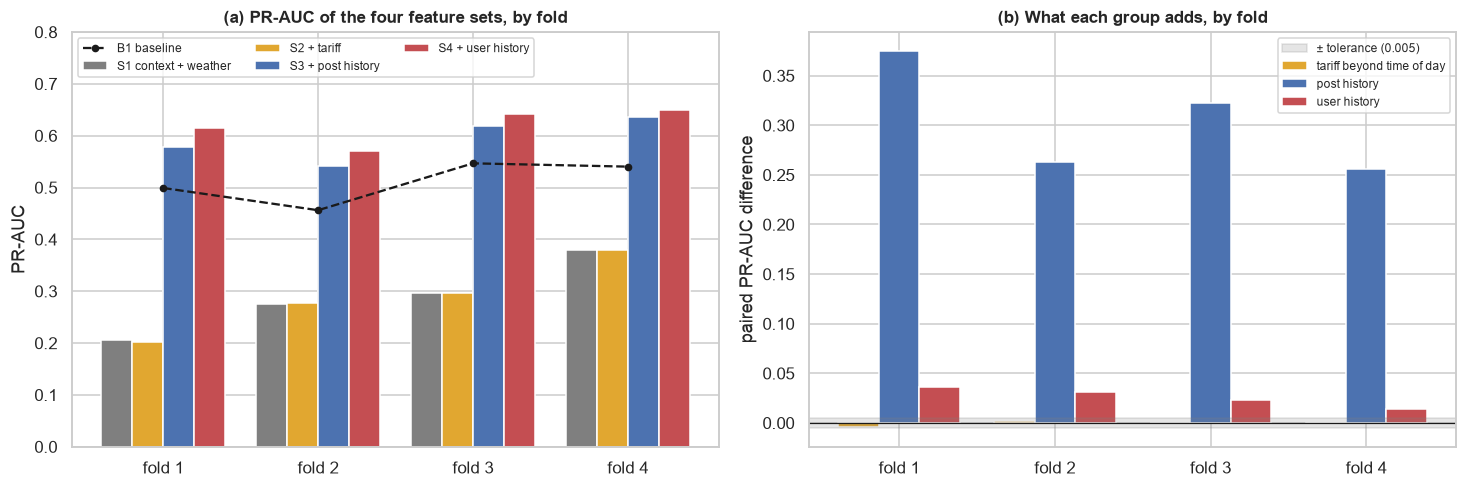

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
colors = [C_GREY, C_ORANGE, C_NORMAL, C_ABN]
width = 0.2
x = np.arange(len(FOLDS))
for i, (label, color) in enumerate(zip(labels, colors)):
    axes[0].bar(x + (i - 1.5) * width, pr.loc[label, [c for c in pr.columns if c != "mean"]], width=width, color=color, label=label)
axes[0].plot(x, metric_table([BASELINES[1]]).iloc[0, :-1], color="k", ls="--", marker="o", ms=4, label="B1 baseline")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 0.8); axes[0].set_title("(a) PR-AUC of the four feature sets, by fold"); axes[0].legend(fontsize=8, loc="upper left", ncol=3)
for i, (question, color) in enumerate(zip(diffs, [C_ORANGE, C_NORMAL, C_ABN])):
    axes[1].bar(x + (i - 1) * 0.26, diffs[question].to_numpy(), width=0.26, color=color, label=question)
axes[1].axhspan(-TOLERANCE, TOLERANCE, color=C_GREY, alpha=0.2, label=f"± tolerance ({TOLERANCE})")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[1].set_ylabel("paired PR-AUC difference")
axes[1].set_title("(b) What each group adds, by fold"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "03_2_ablation")

The contextual and weather variables alone are weak. S1 reaches a mean PR-AUC of 0.289 (lift 1.6, ROC-AUC 0.66), and its fold values go from 0.206 in fold 1,
barely above the abnormal share of that quarter (0.168, a lift of 1.2), to 0.379 in fold 4 (lift 1.8). Even the best case is below the baseline B1, which only uses
the 7-day failure rate of the post (0.511).

**Tariff.** The tariff gives no information beyond the time of day. Adding `tariff_period` to S1 changes the PR-AUC by -0.0001 on average (and the ROC-AUC by -0.0016), and the
fold differences go from -0.0038 to +0.0024, all smaller than the sampling noise of Section 3.3. This is what we expected: the tariff period is a deterministic function of the
start hour (Task 1, Section 4.3), so a model that already has `hour` can rebuild it.

**Post history.** The post history is by far the largest contribution. It lifts the mean PR-AUC from 0.289 to 0.593 (+0.304), the ROC-AUC from 0.659 to 0.810 and the lift from 1.6 to 3.3.
The gain is large in every quarter (+0.375, +0.263, +0.323 and +0.256), and S3 is above the baseline B1 in all four folds (by +0.072 to +0.095). So the model does more than repeat the 7-day failure rate.

**User history.** The user history adds a smaller but consistent benefit: +0.026 in PR-AUC (0.593 to 0.619) and +0.025 in ROC-AUC, positive in all four folds. The gain falls
quarter after quarter (+0.037, +0.031, +0.023, +0.014) and in the last fold it is about a third of what it was in the first. The data do not tell us why. One possibility is that the
post history becomes more informative in later folds (the S3 PR-AUC rises from 0.577 to 0.635), which leaves less for the user history to add. Either way, the user history is not a growing source of information.

**Consistency over time.** The ordering of the sets is the same in every fold: S1 and S2 are tied, S3 is far above them and S4 is above S3. The size of the post-history gain varies by 0.12 between quarters,
and the user-history gain shrinks, so the conclusions are consistent in direction but not in size.

### 3.3 How large is the noise of a PR-AUC?

A difference is only worth reading if it is larger than the sampling noise of the metric. We estimate that noise with a bootstrap of the validation
quarter (100 resamples of the sessions) for the predictions of S4.

In [9]:
rng_boot = np.random.default_rng(SEED)
boot = []
for f in FOLDS:
    y = df.loc[f["valid"], TARGET].to_numpy()
    p = PREDS[("S4 + user history", f["fold"])]
    scores = [average_precision_score(y[i], p[i]) for i in (rng_boot.integers(0, len(y), len(y)) for _ in range(100))]
    boot.append({"fold": f["fold"], "validation sessions": len(y), "PR-AUC": average_precision_score(y, p), "bootstrap standard error": np.std(scores, ddof=1)})
boot = pd.DataFrame(boot).set_index("fold")
display(boot.style.format({"validation sessions": "{:,.0f}", "PR-AUC": "{:.3f}", "bootstrap standard error": "{:.4f}"}))

,validation sessions,PR-AUC,bootstrap standard error
fold,,,
1,"60,364",0.614,0.0042
2,"41,797",0.571,0.0058
3,"57,542",0.642,0.0043
4,"75,769",0.650,0.0039


The bootstrap standard error of the PR-AUC of one fold is between 0.004 and 0.006, so the tolerance of 0.005 that we use to call two results tied is about one standard error.
This is conservative for paired differences, because both sets are scored on the same sessions and the noise of their difference is smaller than the noise of each score. The tariff
differences (at most 0.004 in absolute value) are inside this noise, and the post-history and user-history gains are many times larger.

### 3.4 Do `post_id` and the tariff earn their place?

The ablation above keeps `post_id` and `tariff_period` in every set. Two questions remain, one left open in Task 2 (Section 4: *whether `post_id` adds
value is a question for the ablation*) and one raised by Section 3.2: the tariff is a deterministic function of the hour (Task 1, Section 4.3), and
`post_id` is an identifier that a model can memorise and that does not exist for a new post. We test both by removing them from S4, and we also
measure what the user history is worth once those two are gone, which is the cost of the privacy-preserving alternative.

In [10]:
SELECTED = [c for c in S4 if c not in ("post_id", "tariff_period")]
NO_USER = [c for c in SELECTED if c not in GROUPS["user_history"] + GROUPS["concurrency"]]
CHECKS = {"S4 without post_id": [c for c in S4 if c != "post_id"],
          "S4 without post_id and tariff (selected)": SELECTED,
          "selected without user history": NO_USER}
assert [len(f) for f in CHECKS.values()] == [28, 27, 16]

t0 = time.time()
for label, feats in CHECKS.items():
    cv_run(label, make_reference_model, feats)
print(f"three reduction checks x four folds fitted in {time.time() - t0:.0f} s")

all_labels = ["S4 + user history"] + list(CHECKS)
all_metrics = pd.concat(METRICS)
check_summary = all_metrics[all_metrics["model"].isin(all_labels)].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
check_summary.insert(0, "features", [29, 28, 27, 16])
display(check_summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
pr_c = metric_table(all_labels)
fold_cols = [c for c in pr_c.columns if c != "mean"]
rows, check_diffs = [], {}
for question, new, base in [("removing post_id from S4", "S4 without post_id", "S4 + user history"),
                            ("removing the tariff as well", "S4 without post_id and tariff (selected)", "S4 without post_id"),
                            ("removing the user history from the selected set", "selected without user history", "S4 without post_id and tariff (selected)")]:
    d, s = paired(pr_c.loc[new, fold_cols], pr_c.loc[base, fold_cols])
    check_diffs[question] = d
    rows.append({"change": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("change").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))
display(pd.DataFrame(check_diffs).T.rename(columns=lambda c: f"fold {c}").style.format("{:+.4f}"))

three reduction checks x four folds fitted in 22 s


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S4 + user history,29,0.619,3.46,0.835,0.103,0.340
S4 without post_id,28,0.625,3.49,0.836,0.102,0.338
S4 without post_id and tariff (selected),27,0.626,3.50,0.836,0.102,0.337
selected without user history,16,0.601,3.35,0.812,0.106,0.351


,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold
change,,,,
removing post_id from S4,+0.0057,4 of 4,+0.0027,+0.0089
removing the tariff as well,+0.0010,3 of 4,-0.0002,+0.0021
removing the user history from the selected set,-0.0253,0 of 4,-0.0344,-0.0157


,fold fold 1,fold fold 2,fold fold 3,fold fold 4
removing post_id from S4,+0.0050,+0.0027,+0.0061,+0.0089
removing the tariff as well,+0.0018,-0.0002,+0.0001,+0.0021
removing the user history from the selected set,-0.0296,-0.0344,-0.0217,-0.0157


**`post_id`.** Removing it raises the mean PR-AUC from 0.619 to 0.625 (+0.0057), in all four folds (+0.0027 to +0.0089), and it also slightly improves the ROC-AUC, the Brier score and the log-loss.
Once the recent failures of the post are known, its identity adds nothing, and it lets the model memorise the pattern of the training period, which does not stay still (Task 1, Section 7.3:
station levels move a lot). Without it the model can score a session of a new post from its station, district and history. We drop `post_id` and keep `location` and `district`.
This answers the question left open in Task 2 (Section 4).

**The tariff.** Removing it as well changes the PR-AUC by +0.0010, with a gain in three folds and a loss of 0.0002 in the fourth. This is inside the tolerance, so the tariff earns no place: we drop it, which also
removes a redundant variable.

**The selected set.** The 27 features (S4 without `post_id` and `tariff_period`) give the best result of all variants: PR-AUC 0.626, lift 3.50, ROC-AUC 0.836, Brier score 0.102 and log-loss 0.337.

**The cost of leaving out the user history.** Without the 11 user variables, the selected set gives a PR-AUC of 0.601 and a ROC-AUC of 0.812. The loss of 0.025 is larger than the tolerance in all four folds (-0.016 to -0.034),
so by our rule the user history stays in the modelling set. The privacy-preserving version is still 0.09 above the baseline B1 (0.601 against 0.511), which matters for the discussion in Section 3.6.

### 3.5 Does the user history help everyone? Cold start

The user history is empty for a new account (`is_new_user = 1`, about 13% of the sessions), so it cannot help those sessions. The table splits the
validation predictions of S3 and S4, pooled over the four folds, into new and returning users.

In [11]:
def segment_scores(label):
    y = np.concatenate([df.loc[f["valid"], TARGET].to_numpy() for f in FOLDS])
    p = np.concatenate([PREDS[(label, f["fold"])] for f in FOLDS])
    new = np.concatenate([df.loc[f["valid"], "is_new_user"].to_numpy() for f in FOLDS])
    return y, p, new


rows = []
for label in ["S3 + post history", "S4 + user history"]:
    y, p, new = segment_scores(label)
    for flag, name in [(1, "new users"), (0, "returning users")]:
        m = new == flag
        rows.append({"feature set": label, "segment": name, "sessions": int(m.sum()), "abnormal share": y[m].mean(),
                     "PR-AUC": average_precision_score(y[m], p[m]), "ROC-AUC": roc_auc_score(y[m], p[m])})
cold = pd.DataFrame(rows).set_index(["feature set", "segment"])
display(cold.style.format({"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}"}))

About 13% of the validation sessions (29,685 of 235,472) are from new accounts. They are harder to predict: their abnormal share is higher (22.4% against 17.8%) and the scores are lower. With S4, the PR-AUC is 0.526 and
the ROC-AUC 0.734 for new users, against 0.644 and 0.849 for returning users.

The user history helps only the second group. For new users, S3 and S4 are tied (PR-AUC 0.524 and 0.526, ROC-AUC 0.737 and 0.734), which is expected, since their history is empty. For returning users S4 is better
than S3 by +0.027 in PR-AUC and +0.026 in ROC-AUC. So the whole benefit of the user history of Section 3.2 comes from returning users, and a model that uses it gives a better risk estimate to a returning driver than to a new one.

### 3.6 Operational and ethical concerns of each group

The brief asks which groups raise operational or ethical concerns. The table combines the conditions needed to run each group at the start of a session, the concerns, and the evidence of this notebook.

| Group | What is needed to run it | Operational or ethical concern | Evidence in this notebook | Our position |
|-------|--------------------------|--------------------------------|---------------------------|--------------|
| Calendar | Nothing: it comes from the start time | None | Part of S1, which is weak on its own (PR-AUC 0.289) | Keep |
| Station and district (`location`, `district`) | The post is known when the car is plugged in | No personal data. If alerts steer maintenance, attention concentrates on the stations with the highest risk (from about 8% to 38% abnormal in Task 1, Section 9.1), so the alerts per station should be monitored | Part of every set | Keep |
| `post_id` | The post identifier | It identifies one device and lets the model memorise it, and it does not exist for a new post | Removing it raised PR-AUC by +0.0057 in 4 of 4 folds (Section 3.4) | Drop |
| Weather | A daily forecast per district at the start (an assumption of the brief) | None for people. If it were an observed daily total, it would contain information from after the start | Part of S1, low value | Keep, with the assumption stated |
| Tariff | Nothing: it comes from the start time | None | Adds nothing beyond the hour (Section 3.2) | Drop, because it is redundant |
| Post history | A live record of the completed sessions of each post with their outcomes. A label exists only when a session ends, up to 24 hours later, so the record is always slightly behind. Posts without history (new ones) cannot use it | No personal data. There is a feedback effect: if alerts lead to maintenance, the failures fall and the history changes, so the model also reflects the maintenance policy | Largest contribution: +0.304 PR-AUC, in all four folds | Keep |
| User history and concurrency | The account must be identified when the session starts, and the platform must keep the outcomes of each account | It is a behaviour profile tied to a persistent identifier, which conflicts with data minimisation and purpose limitation (as in the GDPR). A driver who met a faulty post gets a higher risk, so the user can be blamed for a failure of the infrastructure. New users (13% of the sessions) cannot be scored with it (Section 3.5) | +0.026 PR-AUC, positive in 4 of 4 folds but shrinking from +0.037 to +0.014, and only for returning users | Keep it in the comparison, because the rule requires it, but use it only for an internal ranking and never for a decision about a driver. The user-free set is the fallback (PR-AUC 0.601) |

In [12]:
log_decision("3", "Ablation design", "Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.",
             "Reference model handles categories, NaN and interactions; the tolerance is about one bootstrap standard error of a fold PR-AUC (Section 3.3).")
log_decision("3", "Selected feature set",
             "27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).",
             "Removing post_id raised PR-AUC in 4 of 4 folds, removing the tariff changed it by less than the tolerance; the post history adds about +0.30 and the user history about +0.03 in all four folds (Sections 3.2 and 3.4).")

---
## 4. Individual models

### 4.1 Which classifiers, and why

The brief lists five modelling principles (linear, probabilistic, instance-based, decision trees and kernel-based) and asks for at least three,
chosen and justified, instead of many without analysis. We choose three: a linear classifier, a probabilistic classifier and a decision tree. The
choice depends on what the data look like. The 27 selected features mix two categories (station and district), two circular calendar variables, weather,
skewed counts and times (Task 1, Section 9.4), bounded rates and four variables with structural missing values. About 18.5% of the sessions are
abnormal, which is a moderate imbalance. In Task 1 we decided not to resample, so the classifiers use the natural class prior and we judge them with
ranking metrics (PR-AUC, ROC-AUC) and with probability metrics (Brier score, log-loss).

| Principle | Classifier | Why it fits this problem | Assumption and risk here | Interpretability | Cost on 270k training sessions |
|-----------|------------|--------------------------|--------------------------|------------------|--------------------------------|
| Linear | Logistic regression (L2) | The failure rate of a post rises smoothly with its recent failure rate (decile curves of Task 1, Section 9.4), which a linear log-odds can follow. It outputs probabilities, which the Brier score and the cut-off `t* = 1/(1 + c)` of Task 2 need | The log-odds must be linear in the inputs, so the skewed variables need a log transform, and the U-shape of the time since the previous session is not linear. Correlated windows make single coefficients unstable (the long user windows have a VIF above 10 in Task 1, Section 12.4), and the L2 penalty controls that | High: one coefficient per input | Low: seconds |
| Probabilistic | Naive Bayes (categorical, Laplace estimate) | Few parameters, a probabilistic output and a different inductive bias from the other two. It handles the mixed types once the numbers are discretised, which is the equal-frequency binning of the course | It assumes the inputs are independent given the class. They are not: the 1-, 7- and 30-day windows overlap and fleet accounts repeat. We reduce the numeric inputs to the set without strong correlations (|ρ| < 0.9, Task 1, Section 12), and we expect overconfident probabilities | Medium: one likelihood table per input | Low: seconds |
| Decision tree | CART tree | Thresholds on rates and gaps and their interactions (for example "recent post failure rate high and short gap since the previous session") match the shapes seen in Task 1. Missing values and the unordered scale of the codes cause no trouble, and no scaling is needed | A single deep tree is unstable (small changes in the data give another tree) and overfits, so depth and leaf size are chosen on the folds | High: rules can be read | Low: seconds |

**Classifiers left out, with the reason.** *k-nearest neighbours* (instance-based) needs a distance on scaled, skewed and mixed inputs, and each of the
40–76k validation sessions of a fold would have to be compared with up to 270k training sessions. Subsampling the training data to make it fast would
throw away the history that gives the signal. A *kernel SVM* (kernel-based) takes a time between quadratic and cubic in the number of training sessions,
which is not feasible at this size without subsampling, and it returns scores and not probabilities. We therefore cover three of the five principles.

### 4.2 Preprocessing of each classifier

Every step that learns from data is fitted inside the training part of each fold, through a pipeline (Task 2, Section 7.3).

* Logistic regression uses the linear view of Task 1 (Section 13): caps at the 0.1th and 99.9th training percentiles for the heavy-tailed variables, the
  training maximum for the structural missing values (the indicator variables stay in the model), `log1p` for the skewed variables, z-scores, one-hot codes
  for station and district, and sine and cosine of hour and day of week.
* Naive Bayes uses the numeric variables of the reduced set of Task 1 (without strong correlations), discretised into 10 equal-frequency bins learned on the
  training rows, with the binary variables, hour, day of week, station and district as categories and a Laplace estimate of 1.
* The decision tree uses the tree view of Section 3: ordinal codes for station and district, missing values kept.

In [13]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles learned on the training rows. NaN are preserved."""

    def __init__(self, lower=0.001, upper=0.999):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lower, axis=0), np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class MaxImputer(BaseEstimator, TransformerMixin):
    """Replace NaN by the column maximum of the training rows ("the event never happened" is the far end of the observed range)."""

    def fit(self, X, y=None):
        self.fill_ = np.nanmax(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        rows, cols = np.where(np.isnan(X))
        X[rows, cols] = self.fill_[cols]
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


CIRCULAR = {"hour": 24, "dow": 7}


def circular_encode(X):
    """(sin, cos) of 2π·x/period for hour and day of week (stateless)."""
    X = np.asarray(X, dtype=float)
    periods = np.array([CIRCULAR[c] for c in CIRCULAR], dtype=float)
    angle = 2 * np.pi * X / periods
    return np.column_stack([f(angle[:, j]) for j in range(X.shape[1]) for f in (np.sin, np.cos)])


def circular_names(transformer, input_features):
    return np.array([f"{n}_{s}" for n in input_features for s in ("sin", "cos")], dtype=object)


def split_features(features):
    categorical = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    circular = [c for c in features if c in CIRCULAR]
    numeric = [c for c in features if c not in categorical and c not in circular]
    return categorical, numeric, circular


def linear_view(features):
    """Preprocessing of logistic regression (Task 1, Section 13): caps, max-fill, log1p, z-score, one-hot, sine/cosine."""
    categorical, numeric, circular = split_features(features)
    log_cols = [c for c in numeric if c in FEATURE_GROUPS["log1p"]]
    cap_cols = [c for c in numeric if c == "user_active_sessions_at_start"]
    binary_cols = [c for c in numeric if c in FEATURE_GROUPS["binary"]]
    scale_cols = [c for c in numeric if c not in log_cols + cap_cols + binary_cols]
    steps = [("log", Pipeline([("cap", Winsorizer()), ("fill", MaxImputer()),
                               ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), log_cols),
             ("cap", Pipeline([("cap", Winsorizer()), ("scale", StandardScaler())]), cap_cols),
             ("scale", StandardScaler(), scale_cols), ("binary", "passthrough", binary_cols),
             ("circular", FunctionTransformer(circular_encode, feature_names_out=circular_names), circular),
             ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False, dtype=float), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


REDUCED = set(FEATURE_GROUPS["linear_reduced_numeric"])     # numeric variables without strong correlations (Task 1, Section 12)


def naive_bayes_view(features):
    """Preprocessing of Naive Bayes: reduced numeric set in 10 equal-frequency bins, everything else as integer categories."""
    categorical, numeric, circular = split_features(features)
    continuous = [c for c in numeric if c in REDUCED and c not in FEATURE_GROUPS["binary"]]
    binary = [c for c in numeric if c in REDUCED and c in FEATURE_GROUPS["binary"]]
    steps = [("bins", Pipeline([("fill", MaxImputer()), ("bin", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile"))]), continuous),
             ("pass", "passthrough", binary + circular),
             ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=999, dtype=float), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


def make_logistic(C):
    return lambda features: Pipeline([("prep", linear_view(features)), ("clf", LogisticRegression(C=C, max_iter=500))])


def make_naive_bayes(features):
    return Pipeline([("prep", naive_bayes_view(features)), ("clf", CategoricalNB(alpha=1.0, min_categories=1000))])


def make_tree(depth):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, random_state=SEED))])


print(f"All three classifiers are fitted on the {len(SELECTED)} selected features (Naive Bayes keeps only the numeric ones of the reduced set).")

All three classifiers are fitted on the 27 selected features (Naive Bayes keeps only the numeric ones of the reduced set).


### 4.3 Hyperparameters and the selection rule

We tune only the setting that controls the complexity of each classifier, on a short grid, with the folds of Task 2. The grids are ordered from the
simplest to the most complex configuration. The rule is the one of Task 2 made operational: we take the configuration with the highest unweighted mean
PR-AUC, and if a simpler one is within the tolerance of 0.005 of it (the noise level of Section 3.3), we keep the simpler one. Naive Bayes has no
complexity setting that we vary (the Laplace estimate of 1 and 10 bins are the course defaults).

| Classifier | Grid (simple to complex) | Fixed |
|------------|--------------------------|-------|
| Logistic regression | `C` = 0.01, 1 (a smaller `C` is a stronger penalty) | L2 penalty, 500 iterations |
| Naive Bayes | none | Laplace estimate 1, 10 equal-frequency bins |
| Decision tree | maximum depth 4, 6, 8, 12 | at least 100 sessions per leaf |

In [14]:
def select_simplest(labels):
    """Highest mean PR-AUC; if a simpler configuration (earlier in `labels`) is within TOLERANCE of it, keep the simplest such one."""
    means = metric_table(labels)["mean"]
    best = means.max()
    return next(label for label in labels if means[label] >= best - TOLERANCE)


def config_table(labels, chosen):
    """Per-fold PR-AUC and the mean of the other metrics for a grid of configurations, with the chosen one marked."""
    t = metric_table(labels)
    all_metrics = pd.concat(METRICS)
    other = all_metrics[all_metrics["model"].isin(labels)].groupby("model")[["ROC-AUC", "Brier", "log-loss"]].mean().loc[labels]
    t = t.join(other)
    t["chosen"] = ["yes" if label == chosen else "" for label in labels]
    return t


t0 = time.time()
GRIDS = {"Logistic regression": [(f"LR C={c}", make_logistic(c)) for c in (0.01, 1.0)],
         "Naive Bayes": [("NB", make_naive_bayes)],
         "Decision tree": [(f"DT depth={d}", make_tree(d)) for d in (4, 6, 8, 12)]}
CHOSEN, FACTORY = {}, {}
for name, grid in GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"individual models fitted in {time.time() - t0:.0f} s")

Logistic regression: chosen configuration = LR C=0.01


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
LR C=0.01,0.590,0.534,0.615,0.630,0.592,0.825,0.106,0.350,yes
LR C=1.0,0.590,0.534,0.615,0.630,0.592,0.825,0.106,0.350,


Naive Bayes: chosen configuration = NB


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
NB,0.545,0.478,0.540,0.569,0.533,0.815,0.158,0.728,yes


Decision tree: chosen configuration = DT depth=8


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
DT depth=4,0.534,0.481,0.570,0.576,0.540,0.791,0.108,0.360,
DT depth=6,0.574,0.524,0.608,0.621,0.582,0.819,0.105,0.349,
DT depth=8,0.586,0.544,0.624,0.635,0.597,0.824,0.105,0.347,yes
DT depth=12,0.586,0.545,0.625,0.639,0.599,0.821,0.106,0.354,


individual models fitted in 31 s


**Logistic regression.** The penalty has no visible effect: `C = 0.01` and `C = 1` give the same PR-AUC in every fold (0.592 on average), so we keep the stronger penalty as the simpler model. With more than 100,000 training
sessions and fewer than 50 inputs, the data dominate the penalty. Its ROC-AUC is 0.825 and its Brier score 0.106.

**Naive Bayes.** It ranks the sessions reasonably (ROC-AUC 0.815) but its PR-AUC (0.533) is far below the other two, and its probabilities are bad: the Brier score is 0.158 and the log-loss about 0.73, both worse than predicting the training
prior for every session (B0: 0.148 and 0.472). This is the overconfidence that we expected from the independence assumption, because the 1-, 7- and 30-day windows describe the same events several times and each one adds its own evidence.
It beats B1 in three of the four folds and by only +0.022. Without a calibration step, its scores cannot be used with the cost-based cut-off of Task 2.

**Decision tree.** Depth 4 and 6 underfit (0.540 and 0.582) and are worse in all four folds. Depth 8 (0.597) and depth 12 (0.599) are tied (a difference of 0.002), and the log-loss of depth 12 is worse (0.354 against 0.347),
which is a sign of overfitting. By our rule we keep depth 8.

**The three together.** The tree (0.597) and the logistic regression (0.592) differ by about 0.005, which is the size of the tolerance, although one is non-linear and one is linear. Both are 0.08 to 0.09 above B1
and have the same ROC-AUC (0.824 and 0.825). This suggests that most of the signal in the features is a smooth increase of the risk with the recent failure rates, which both can follow, and that the features, more than the algorithm,
set the level of the result.

In [15]:
log_decision("4", "Individual models",
             "Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.",
             "Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles.")
log_decision("4", "Hyperparameters of the individual models",
             "Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.",
             "Tolerance equals one bootstrap standard error of a fold PR-AUC (Section 3.3); the grids are in Section 4.3.")

---
## 5. Ensemble models

### 5.1 Which ensembles, and why each one could help

The brief asks for at least three ensemble approaches that represent different principles. We choose one for each of three ideas: reducing the
variance of a model (bagging), reducing its bias (boosting) and combining models of different kinds (stacking). Each ensemble is compared with its
own constituents, because that is the improvement the brief asks us to explain.

| Ensemble | Principle | Constituents | Why it could improve on them | What can go wrong |
|----------|-----------|--------------|------------------------------|-------------------|
| Random forest | Bagging with random feature subsets | 200 decision trees, each fitted on a bootstrap sample and each split chosen among a random subset of features | A single tree is unstable (Section 4.1). Averaging many trees that are fitted on different samples and look at different features cancels much of their individual noise, so the variance falls while the bias of a deep tree stays low | Less interpretable than one tree. Correlated trees (strong features dominate) limit the gain |
| Gradient boosting | Boosting | Many shallow trees added one after another, each one fitted to the errors of the sum of the previous ones | A shallow tree is too simple (high bias). Adding trees that correct the remaining errors lets the model capture interactions that no single tree reaches | It can overfit. We fix the number of iterations and do not use the internal early stopping, because that splits the training rows at random and lets later sessions decide when to stop for earlier ones |
| Stacking | Combination of different model kinds with a meta-model | Logistic regression, Naive Bayes and the decision tree of Section 4, combined by a logistic regression on their predictions | The three constituents are wrong in different ways: one is linear, one multiplies independent pieces of evidence, one uses thresholds. A meta-model can learn how much to trust each | The predictions that train the meta-model must not come from models that saw those sessions or later ones. A random inner cross-validation would break that rule, so we build them in time order (Section 5.3) |

Soft or hard voting is not used: it gives every model the same weight, which is a poor choice when one constituent (Naive Bayes) is much weaker than the others,
and stacking learns the weights instead.

### 5.2 Random forest and gradient boosting

As in Section 4.3, we tune only the settings that control complexity, with the same selection rule.

| Ensemble | Grid (simple to complex) | Fixed |
|----------|--------------------------|-------|
| Random forest | at least 200 or 50 sessions per leaf | 200 trees, √(features) per split, 100% bootstrap samples |
| Gradient boosting | (depth 3, learning rate 0.1, 200 iterations), (depth 6, 0.1, 200), (depth 6, 0.05, 300) | at least 100 sessions per leaf, no early stopping |

Both use the tree view of Section 3 (ordinal codes for station and district, missing values kept). Gradient boosting treats the two codes as categories.

In [16]:
def make_forest(leaf):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, max_features="sqrt",
                                                                     n_jobs=-1, random_state=SEED))])


def make_boosting(depth, rate, iterations):
    def factory(features):
        cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
        return Pipeline([("prep", tree_view(features)),
                         ("clf", HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=iterations, min_samples_leaf=100,
                                                                categorical_features=cat or None, random_state=SEED))])
    return factory


t0 = time.time()
ENSEMBLE_GRIDS = {"Random forest": [(f"RF leaf={leaf}", make_forest(leaf)) for leaf in (200, 50)],
                  "Gradient boosting": [(f"HGB depth={d}, lr={lr}, {it} it", make_boosting(d, lr, it)) for d, lr, it in ((3, 0.1, 200), (6, 0.1, 200), (6, 0.05, 300))]}
for name, grid in ENSEMBLE_GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"random forest and gradient boosting fitted in {time.time() - t0:.0f} s")

Random forest: chosen configuration = RF leaf=50


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
RF leaf=200,0.611,0.559,0.640,0.656,0.616,0.834,0.103,0.341,
RF leaf=50,0.615,0.567,0.646,0.662,0.622,0.835,0.102,0.339,yes


Gradient boosting: chosen configuration = HGB depth=6, lr=0.1, 200 it


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
"HGB depth=3, lr=0.1, 200 it",0.615,0.567,0.644,0.654,0.620,0.835,0.103,0.339,
"HGB depth=6, lr=0.1, 200 it",0.621,0.574,0.649,0.661,0.626,0.836,0.102,0.337,yes
"HGB depth=6, lr=0.05, 300 it",0.621,0.573,0.649,0.662,0.626,0.836,0.102,0.337,


random forest and gradient boosting fitted in 135 s


The random forest keeps the smaller leaf: 50 sessions per leaf (0.622) beats 200 (0.616) in all four folds, by more than the tolerance. Gradient boosting with depth 3 is lower (0.620), and the two depth-6 settings are tied at
0.626, so we keep the one with fewer iterations. The two best ensembles are close: the difference between gradient boosting and the random forest is +0.0035, below the tolerance.

### 5.3 Stacking without leakage

The brief warns that the predictions used to train the meta-model must be generated without leakage, and that a standard random inner cross-validation
is not appropriate when future sessions can influence the predictions for earlier ones. We build the meta-training predictions in time order, inside the
training window of each outer fold:

1. The training window is cut into calendar quarters, starting at the end of the burn-in (2020-Q2, 2020-Q3, and so on).
2. For every quarter after the first, the three base models are fitted on the labelled sessions that started and ended before that quarter, and they predict
   that quarter. Every prediction therefore comes from models that have not seen that quarter or anything after it.
3. The meta-model, a logistic regression on the logits of the three predictions, is trained on the predictions of all these inner quarters.
4. The base models are then refitted on the whole training window and predict the validation quarter of the outer fold. The meta-model combines them.

The first quarter has no prediction, because there is nothing before it to train on, so it is used only as training data. Sessions whose label is not
known yet at the start of the validation quarter are removed from the meta-training rows, exactly as in the purge of Task 2. The cost of this design is
that the base models inside the inner quarters see less data (3 to 12 months) than the refitted ones, so the meta-model learns from slightly weaker
predictions than the ones it will combine.

In [17]:
INNER_BOUNDS = [BURN_IN_END + pd.DateOffset(months=3 * i) for i in range(6)]      # quarter boundaries up to the start of fold 4
assert INNER_BOUNDS[-1] == FOLDS[-1]["lo"]
BASES = {"LR": FACTORY[CHOSEN["Logistic regression"]], "NB": FACTORY[CHOSEN["Naive Bayes"]], "DT": FACTORY[CHOSEN["Decision tree"]]}
STACK_LABEL = "Stacking (LR + NB + DT)"


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def stacking_fold(fold):
    """Meta-model trained on out-of-fold predictions built in time order, then applied to the validation quarter of the fold."""
    lo = fold["lo"]
    meta_x, meta_y, quarters = [], [], []
    for a, b in zip(INNER_BOUNDS[1:], INNER_BOUNDS[2:]):
        if b > lo:
            break
        inner_train = df[(df["start_time"] < a) & (df["end_time"] < a)]                  # labelled before the quarter starts
        block = df[(df["start_time"] >= a) & (df["start_time"] < b) & (df["end_time"] < lo)]   # label known when the fold's training is fixed
        assert inner_train["end_time"].max() < a <= block["start_time"].min() and block["end_time"].max() < lo     # leakage checks
        columns = [factory(SELECTED).fit(inner_train[SELECTED], inner_train[TARGET]).predict_proba(block[SELECTED])[:, 1] for factory in BASES.values()]
        meta_x.append(np.column_stack(columns))
        meta_y.append(block[TARGET].to_numpy())
        quarters.append((a, b))
    meta = LogisticRegression(C=1.0, max_iter=500).fit(logit(np.vstack(meta_x)), np.concatenate(meta_y))
    tr, va = df.loc[fold["train"]], df.loc[fold["valid"]]
    base_pred = np.column_stack([factory(SELECTED).fit(tr[SELECTED], tr[TARGET]).predict_proba(va[SELECTED])[:, 1] for factory in BASES.values()])
    return meta.predict_proba(logit(base_pred))[:, 1], meta, quarters, len(np.concatenate(meta_y))


t0 = time.time()
rows, coefficients, STACK_QUARTERS = [], [], {}
for f in FOLDS:
    started = time.time()
    p, meta, quarters, n_meta = stacking_fold(f)
    seconds = time.time() - started
    PREDS[(STACK_LABEL, f["fold"])] = p
    va = df.loc[f["valid"]]
    rows.append({"model": STACK_LABEL, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds, **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    coefficients.append({"fold": f["fold"], "inner quarters": len(quarters), "meta-training sessions": n_meta,
                         **{f"weight {k}": c for k, c in zip(BASES, meta.coef_[0])}, "intercept": meta.intercept_[0]})
    STACK_QUARTERS[f["fold"]] = quarters
METRICS.append(pd.DataFrame(rows))
print(f"stacking fitted in {time.time() - t0:.0f} s; all leakage checks of the inner quarters passed")
display(pd.DataFrame(coefficients).set_index("fold").style.format({"meta-training sessions": "{:,.0f}", "weight LR": "{:.2f}", "weight NB": "{:.2f}", "weight DT": "{:.2f}", "intercept": "{:.2f}"}))

stacking fitted in 25 s; all leakage checks of the inner quarters passed


,inner quarters,meta-training sessions,weight LR,weight NB,weight DT,intercept
fold,,,,,,
1,1,"67,788",0.65,0.03,0.31,0.04
2,2,"128,150",0.60,0.02,0.39,0.05
3,3,"169,959",0.58,0.01,0.43,0.06
4,4,"227,500",0.56,-0.00,0.47,0.06


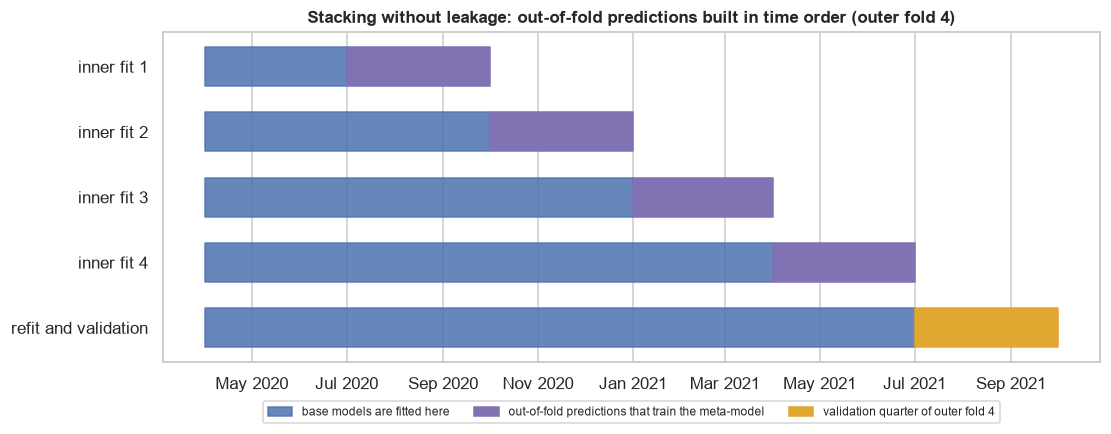

In [18]:
fig, ax = plt.subplots(figsize=(11, 3.9))
d2n = mdates.date2num
quarters = STACK_QUARTERS[4]
for i, (a, b) in enumerate(quarters):
    y0 = len(quarters) + 1 - i
    ax.broken_barh([(d2n(BURN_IN_END), d2n(a) - d2n(BURN_IN_END))], (y0 - 0.3, 0.6), color=C_NORMAL, alpha=0.85)
    ax.broken_barh([(d2n(a), d2n(b) - d2n(a))], (y0 - 0.3, 0.6), color=C_PURPLE)
f4 = FOLDS[3]
ax.broken_barh([(d2n(BURN_IN_END), d2n(f4["lo"]) - d2n(BURN_IN_END))], (0.7, 0.6), color=C_NORMAL, alpha=0.85)
ax.broken_barh([(d2n(f4["lo"]), d2n(f4["hi"]) - d2n(f4["lo"]))], (0.7, 0.6), color=C_ORANGE)
ax.set_yticks(list(range(len(quarters) + 1, 1, -1)) + [1])
ax.set_yticklabels([f"inner fit {i + 1}" for i in range(len(quarters))] + ["refit and validation"])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_NORMAL, alpha=0.85), plt.Rectangle((0, 0), 1, 1, color=C_PURPLE), plt.Rectangle((0, 0), 1, 1, color=C_ORANGE)],
          labels=["base models are fitted here", "out-of-fold predictions that train the meta-model", "validation quarter of outer fold 4"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
ax.set_title("Stacking without leakage: out-of-fold predictions built in time order (outer fold 4)")
savefig(fig, "05_3_stacking_design")

The meta-model learns to ignore Naive Bayes: its weight falls from 0.03 to 0.00 over the four folds, while the logistic regression gets between 0.56 and 0.65 and the tree between 0.31 and 0.47. The weight of the tree rises with the size of
the training window (0.31 in fold 1, 0.47 in fold 4), as the tree itself improves with more data, and the weight of the logistic regression falls. The meta-training sets have from 67,788 sessions (fold 1, one inner quarter) to 227,500 (fold 4, four inner quarters).
In every fold the stacking is better than each of its constituents, but it stays below the random forest and gradient boosting (Section 5.4).

### 5.4 Does each ensemble improve on its constituents?

The table gives the paired difference in PR-AUC between each ensemble and the constituent models that it is built from, fold by fold.

In [19]:
FINAL = {"Logistic regression": CHOSEN["Logistic regression"], "Naive Bayes": CHOSEN["Naive Bayes"], "Decision tree": CHOSEN["Decision tree"],
         "Random forest": CHOSEN["Random forest"], "Gradient boosting": CHOSEN["Gradient boosting"], "Stacking": STACK_LABEL}
table = metric_table(list(FINAL.values()))
fold_cols = [c for c in table.columns if c != "mean"]
pairs = [("Random forest", "Decision tree"), ("Gradient boosting", "Decision tree"), ("Gradient boosting", "Random forest"),
         ("Stacking", "Logistic regression"), ("Stacking", "Naive Bayes"), ("Stacking", "Decision tree")]
rows, ensemble_diffs = [], {}
for ensemble, constituent in pairs:
    d, s = paired(table.loc[FINAL[ensemble], fold_cols], table.loc[FINAL[constituent], fold_cols])
    ensemble_diffs[f"{ensemble} − {constituent}"] = d
    rows.append({"comparison": f"{ensemble} − {constituent}", "PR-AUC difference (mean)": s["mean difference"], "folds won": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("comparison").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))

,PR-AUC difference (mean),folds won,smallest fold,largest fold
comparison,,,,
Random forest − Decision tree,+0.0251,4 of 4,+0.0220,+0.0289
Gradient boosting − Decision tree,+0.0285,4 of 4,+0.0247,+0.0343
Gradient boosting − Random forest,+0.0035,3 of 4,-0.0014,+0.0072
Stacking − Logistic regression,+0.0180,4 of 4,+0.0122,+0.0210
Stacking − Naive Bayes,+0.0774,4 of 4,+0.0576,+0.0957
Stacking − Decision tree,+0.0130,4 of 4,+0.0113,+0.0157


All three ensembles improve on their constituents in every fold.
* The random forest is +0.025 above the decision tree (+0.022 to +0.029), and gradient boosting is +0.029 above it (+0.025 to +0.034). The forest reduces the variance that makes a single tree unstable, and boosting adds trees that correct the remaining errors.
* The stacking is above the logistic regression by +0.018, above the tree by +0.013 and above Naive Bayes by +0.078, in all four folds. The gain over the best constituent is the smallest of the three ensembles, and the meta-model gives almost no weight to Naive Bayes,
  so the combination is in practice a mix of the linear model and the tree.
* Gradient boosting and the random forest are tied: +0.0035 for boosting, ahead in three folds and behind by 0.0014 in the other.

The ensembles of trees gain more than the one that mixes different kinds of model. A possible reason is that the constituents of the stacking were fitted on the same features and, as Section 4 showed, they were limited by the information in those features, and not by their principle.

In [20]:
log_decision("5", "Ensembles",
             "Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.",
             "One ensemble per principle (variance reduction, bias reduction, model combination); each is compared with its own constituents (Section 5.4).")
log_decision("5", "Leakage-free stacking",
             "Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.",
             "Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.")
log_decision("5", "Boosting without early stopping",
             "Fixed number of iterations; no internal early stopping.",
             "The internal early stopping splits the training rows at random, which lets later sessions decide when to stop for earlier ones.")

---
## 6. Comparison and conclusions

### 6.1 All models under the Task 2 protocol

The table puts the two baselines and the six models side by side with the aggregation rules of Task 2 (Section 8): the unweighted mean PR-AUC ranks the
models, and the weighted mean, the standard deviation across folds, the worst fold and the trend describe how stable the result is. The last two columns
compare each model with the baseline B1 fold by fold.

In [21]:
NAMES = {BASELINES[0]: "B0 no skill", BASELINES[1]: "B1 post failure rate (7 days)",
         **{label: f"{name} ({label})" if name != "Stacking" else label for name, label in FINAL.items()}}
ALL_MODELS = BASELINES + list(FINAL.values())
weights = fold_table["validation sessions"]
all_metrics = pd.concat(METRICS)
pr_all = metric_table(ALL_MODELS)
fold_cols = [c for c in pr_all.columns if c != "mean"]

rows = []
for label in ALL_MODELS:
    s = summarise_folds(pr_all.loc[label, fold_cols].to_numpy(), weights.to_numpy())
    other = all_metrics[all_metrics["model"] == label][["lift", "ROC-AUC", "Brier", "log-loss", "seconds"]].mean()
    d, ps = paired(pr_all.loc[label, fold_cols], pr_all.loc[BASELINES[1], fold_cols])
    rows.append({"model": NAMES[label], "PR-AUC mean": s["mean (unweighted)"], "weighted": s["mean (weighted by validation sessions)"],
                 "std": s["std across folds"], "worst fold": s["worst fold"], "trend": s["trend per fold"],
                 "lift": other["lift"], "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"],
                 "gain over B1": ps["mean difference"], "folds won vs B1": ps["folds won"], "seconds per fold": other["seconds"]})
comparison = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False)
display(comparison.style.format({"PR-AUC mean": "{:.3f}", "weighted": "{:.3f}", "std": "{:.3f}", "worst fold": "{:.3f}", "trend": "{:+.3f}", "lift": "{:.2f}",
                                 "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}", "gain over B1": "{:+.3f}", "seconds per fold": "{:.1f}"}, na_rep="—"))
print("PR-AUC by fold:")
display(pr_all.rename(index=NAMES).loc[comparison.index].style.format("{:.3f}"))

,PR-AUC mean,weighted,std,worst fold,trend,lift,ROC-AUC,Brier,log-loss,gain over B1,folds won vs B1,seconds per fold
model,,,,,,,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.626,0.632,0.039,0.574,+0.019,3.50,0.836,0.102,0.337,+0.115,4 of 4,2.6
Random forest (RF leaf=50),0.622,0.629,0.042,0.567,+0.022,3.48,0.835,0.102,0.339,+0.112,4 of 4,14.1
Stacking (LR + NB + DT),0.610,0.617,0.042,0.555,+0.022,3.41,0.831,0.104,0.343,+0.100,4 of 4,6.1
Decision tree (DT depth=8),0.597,0.604,0.041,0.544,+0.023,3.34,0.824,0.105,0.347,+0.087,4 of 4,1.4
Logistic regression (LR C=0.01),0.592,0.599,0.042,0.534,+0.020,3.31,0.825,0.106,0.350,+0.082,4 of 4,0.8
Naive Bayes (NB),0.533,0.540,0.039,0.478,+0.013,2.98,0.815,0.158,0.728,+0.022,3 of 4,0.4
B1 post failure rate (7 days),0.511,0.516,0.042,0.456,+0.021,2.85,0.772,0.118,0.385,+0.000,0 of 4,—
B0 no skill,0.181,0.185,0.021,0.162,+0.014,1.01,0.504,0.148,0.472,-0.329,0 of 4,—


PR-AUC by fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.621,0.574,0.649,0.661,0.626
Random forest (RF leaf=50),0.615,0.567,0.646,0.662,0.622
Stacking (LR + NB + DT),0.602,0.555,0.636,0.648,0.610
Decision tree (DT depth=8),0.586,0.544,0.624,0.635,0.597
Logistic regression (LR C=0.01),0.590,0.534,0.615,0.630,0.592
Naive Bayes (NB),0.545,0.478,0.540,0.569,0.533
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511
B0 no skill,0.172,0.162,0.181,0.210,0.181


Gradient boosting (0.626) and the random forest (0.622) are at the top and tied within the tolerance (a difference of 0.004, with boosting ahead in three of the four folds). The stacking (0.610) follows, then the tree (0.597) and the logistic regression
(0.592). Naive Bayes (0.533) is only slightly above B1 (0.511), and B0 is at the abnormal share (0.181). Every model beats B1 in all four folds, except Naive Bayes, which does so in three.

The gain of the best model over B1 is stable: +0.122, +0.118, +0.102 and +0.121 by fold, +0.115 on average (lift 3.5 against 2.85). The standard deviation across folds (0.039 to 0.042) is about the same for every model, including B1 (0.042), and only the no-skill baseline is lower:
the quarters differ in difficulty for all models alike (fold 2 is the worst for every model, and fold 3 or fold 4 is the best), so no model is more stable than another in this sense. The trend per fold is also the same as for B1 (+0.019 against +0.021), so the improvement over
time follows the data (the abnormal share rises) and not the models. The weighted means are 0.004 to 0.007 above the unweighted ones, which means that the ranking is not decided by the largest fold.

For the probabilities, the two best models and the logistic regression have a Brier score of 0.102 to 0.106 and a log-loss of 0.337 to 0.350, and Naive Bayes is worse than the constant prior, as discussed in Section 4.3.
The last column shows the cost of one fold on our machine: gradient boosting takes about 2 seconds and the random forest about 14, between seven and eight times more. The stacking takes about 6 seconds, because it refits the three cheap base models once for every inner quarter.

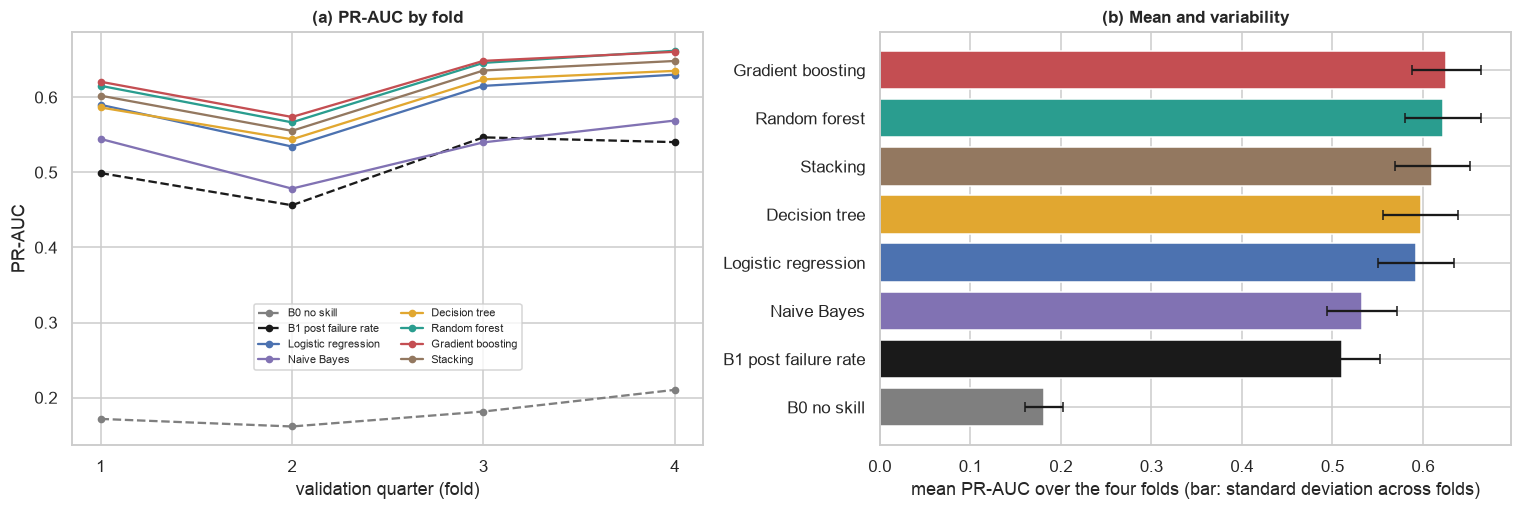

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {BASELINES[0]: C_GREY, BASELINES[1]: "k", FINAL["Logistic regression"]: C_NORMAL, FINAL["Naive Bayes"]: C_PURPLE, FINAL["Decision tree"]: C_ORANGE,
           FINAL["Random forest"]: C_GREEN, FINAL["Gradient boosting"]: C_ABN, FINAL["Stacking"]: "#937860"}
for label in ALL_MODELS:
    axes[0].plot(range(1, 5), pr_all.loc[label, fold_cols], marker="o", ms=4, color=palette[label], ls="--" if label in BASELINES else "-", label=NAMES[label].split(" (")[0])
axes[0].set_xticks(range(1, 5)); axes[0].set_xlabel("validation quarter (fold)"); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) PR-AUC by fold"); axes[0].legend(fontsize=7, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.17))
order = comparison.index[::-1]
inverse = {v: k for k, v in NAMES.items()}
axes[1].barh([n.split(" (")[0] for n in order], comparison.loc[order, "PR-AUC mean"], xerr=comparison.loc[order, "std"], color=[palette[inverse[n]] for n in order], capsize=3)
axes[1].set_xlabel("mean PR-AUC over the four folds (bar: standard deviation across folds)"); axes[1].set_title("(b) Mean and variability")
fig.tight_layout()
savefig(fig, "06_1_model_comparison")

In panel (a) the curves are almost parallel: the models differ by roughly constant gaps, and the dip of fold 2 and the rise towards fold 4 are shared by all of them. In panel (b) the error bars (about 0.04) are much larger than the differences
between the top models, but they mostly show the difference in difficulty between quarters, not uncertainty about the ranking. The ranking is read from the paired differences in Section 5.4 and in the last columns of the table, where that common effect cancels.

### 6.2 What the alerts would look like

The operational measures of Task 2 show what the ranking means for an operator who can review a fixed share of the sessions. The first table gives the
mean precision and recall over the folds at each alert budget, and the second the counts per 1,000 sessions for the model at the top of the ranking.

In [23]:
rows = []
for label in ALL_MODELS:
    sub = all_metrics[all_metrics["model"] == label]
    row = {"model": NAMES[label]}
    for q in ALERT_BUDGETS:
        row[f"precision @{q:.0%}"] = sub[f"precision @{q:.0%}"].mean()
        row[f"recall @{q:.0%}"] = sub[f"recall @{q:.0%}"].mean()
    rows.append(row)
operational = pd.DataFrame(rows).set_index("model").loc[comparison.index]
display(operational.style.format("{:.3f}"))

best_label = inverse[comparison.index[0]]
sub = all_metrics[all_metrics["model"] == best_label]
counts = pd.DataFrame({f"budget {q:.0%}": {"alerts per 1,000": sub[f"alerts per 1,000 @{q:.0%}"].mean(), "correct alerts per 1,000": sub[f"correct alerts per 1,000 @{q:.0%}"].mean(),
                                          "false alerts per 1,000": sub[f"false alerts per 1,000 @{q:.0%}"].mean(), "missed per 1,000": sub[f"missed per 1,000 @{q:.0%}"].mean()}
                       for q in ALERT_BUDGETS})
b1 = all_metrics[all_metrics["model"] == BASELINES[1]]
counts_b1 = pd.DataFrame({f"budget {q:.0%}": {"correct alerts per 1,000": b1[f"correct alerts per 1,000 @{q:.0%}"].mean(), "false alerts per 1,000": b1[f"false alerts per 1,000 @{q:.0%}"].mean(),
                                             "missed per 1,000": b1[f"missed per 1,000 @{q:.0%}"].mean()} for q in ALERT_BUDGETS})
print(f"Counts per 1,000 sessions, mean over the folds, for {NAMES[best_label]}:")
display(counts.style.format("{:.1f}"))
print("and for the baseline B1:")
display(counts_b1.style.format("{:.1f}"))

,precision @5%,recall @5%,precision @10%,recall @10%,precision @20%,recall @20%
model,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.880,0.246,0.721,0.402,0.528,0.587
Random forest (RF leaf=50),0.875,0.245,0.720,0.401,0.528,0.587
Stacking (LR + NB + DT),0.863,0.242,0.713,0.397,0.520,0.578
Decision tree (DT depth=8),0.862,0.241,0.710,0.395,0.515,0.573
Logistic regression (LR C=0.01),0.839,0.235,0.694,0.387,0.515,0.573
Naive Bayes (NB),0.716,0.200,0.626,0.350,0.496,0.552
B1 post failure rate (7 days),0.738,0.207,0.594,0.330,0.451,0.499
B0 no skill,0.182,0.051,0.182,0.101,0.180,0.200


Counts per 1,000 sessions, mean over the folds, for Gradient boosting (HGB depth=6, lr=0.1, 200 it):


,budget 5%,budget 10%,budget 20%
"alerts per 1,000",50.0,100.0,200.0
"correct alerts per 1,000",44.0,72.1,105.7
"false alerts per 1,000",6.0,27.9,94.3
"missed per 1,000",136.1,107.9,74.4


and for the baseline B1:


,budget 5%,budget 10%,budget 20%
"correct alerts per 1,000",36.9,59.4,90.2
"false alerts per 1,000",13.1,40.6,109.8
"missed per 1,000",143.2,120.7,89.9


For a team that can review 5% of the sessions (50 alerts per 1,000), 88% of the alerts of the best model are real failures, against 74% for B1, and 24.6% of all failures are caught (B1: 20.7%). Per 1,000 sessions that is 44 correct alerts, 6 false
alerts and 136 failures that go unnoticed (B1: 37, 13 and 143). With a budget of 10% the precision is 72% and the recall 40% (72 correct, 28 false and 108 missed per 1,000). With 20% it is 53% and 59% (106 correct, 94 false, 74 missed; B1: 90, 110 and 90).

The improvement over B1 is mainly in precision for small budgets (+14 points at 5%, +8 points at 20%), and in the number of false alerts, which falls by 7 per 1,000 at a 5% budget and by 16 at 20%. The random forest and gradient boosting are practically the same in these
measures, and the logistic regression is not far behind (precision 84% at 5%). Even the best model misses most failures when only 5% of the sessions can be reviewed (136 of about 180 per 1,000). This is only a hypothesis, but failures that are not preceded by recent failures at the same post
cannot be anticipated from a history of the post.

### 6.3 Conclusions

* **What carries the prediction.** The recent history of the charging post is by far the most informative group (+0.304 PR-AUC over context, weather and tariff). The user history adds a small but consistent gain (+0.026), which exists only for returning users and is shrinking over
  time. The tariff adds nothing beyond the time of day, and the contextual and weather variables alone are weak (PR-AUC 0.289, lift 1.6).
* **The feature set.** We keep 27 features: the 29 of Task 2 without `post_id` (it lowers the score in every fold and does not exist for a new post) and without `tariff_period` (redundant). A user-free version with 16 features is available (PR-AUC 0.601) for the case that the team decides not to use account histories.
* **Individual models.** A linear model and a decision tree give about the same result (0.592 and 0.597), which suggests that the features set the level of the result. Naive Bayes ranks reasonably but has unusable probabilities.
* **Ensembles.** The three ensembles improve on their constituents in every fold. The random forest and gradient boosting are tied at the top (0.622 and 0.626), and we prefer gradient boosting when there is a tie because it is ahead in three folds, is much cheaper to fit and
  therefore to refit when the failure pattern changes. The stacking (0.610) is below both.
* **Against the baselines.** The best model is +0.115 PR-AUC above B1 in all four folds (lift 3.5 against 2.85) and far above no skill (0.181).
* **The project question.** With only information known at the start, the model identifies a useful share of the failures: at a 5% alert budget, 88% of the alerts are correct, but about three quarters of the failures still go unnoticed, and almost all of the signal comes from the recent history of the post.

### 6.4 Limitations

* **Selection and test.** The feature set and the hyperparameters were chosen with the same four folds that we use to report results, so the scores are slightly optimistic. The unbiased estimate is the evaluation on the test period, which stays untouched until the final task.
* **One model family for the ablation.** The ablation uses gradient boosting with fixed hyperparameters. The conclusions are for that family, although the redundancy of the tariff does not depend on it.
* **Four folds.** The standard deviations and trends are rough, and no p-value can be obtained from them (Task 2, Section 8).
* **No threshold and no calibration study.** The alert budgets are assumptions and we did not choose a decision threshold, so the calibration of the probabilities of the best models still has to be checked before a cost-based cut-off is used.
* **Principles not covered.** Instance-based and kernel-based classifiers were left out by design (Section 4.1).
* **The tolerance.** The value of 0.005 is a practical choice, based on the bootstrap noise of Section 3.3, and not a statistical test.
* **A new post.** Without `post_id` the model can score a new post from its station and district, but its history would be empty, and every post of the folds appears in training, so this case is not tested.
* **Grouping.** We put the concurrency variable with the user history because it describes the account. That is our choice.
* **Extra features.** The brief allows additional leakage-safe features, and we did not explore any.

---
## 7. Saved files and decision log

The results are saved so that the next task can reuse the selected feature set, the selected hyperparameters and the fold-by-fold metrics without
repeating the experiments.

In [24]:
for (label, fold), p in PREDS.items():
    assert len(p) == fold_table.loc[fold, "validation sessions"], (label, fold)       # one prediction per validation session
assert set(SELECTED) <= set(features_all) and "post_id" not in SELECTED and "tariff_period" not in SELECTED
assert df["start_time"].max() < TEST_START                                              # the test period was never loaded

fold_metrics = pd.concat(METRICS).reset_index(drop=True)
fold_metrics.to_csv(OUT_DIR / "task3_fold_metrics.csv", index=False)
results = {
    "protocol": "prepared/task2_protocol.json (folds, metrics, alert budgets); test period not loaded",
    "tolerance": TOLERANCE,
    "ablation": {label: {"features": len(feats), "PR-AUC mean": float(pr.loc[label, "mean"]) if label in pr.index else float(pr_c.loc[label, "mean"])}
                 for label, feats in {**STEPS, **CHECKS}.items()},
    "selected_features": SELECTED,
    "features_without_user_history": NO_USER,
    "selected_configurations": {name: label for name, label in FINAL.items()},
    "comparison": comparison.reset_index().to_dict("records"),
}
(OUT_DIR / "task3_results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task3_decision_log.csv", index=False)
print("Saved:", OUT_DIR / "task3_results.json", OUT_DIR / "task3_fold_metrics.csv", OUT_DIR / "task3_decision_log.csv", "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task3_results.json prepared/task3_fold_metrics.csv prepared/task3_decision_log.csv | figures in prepared/figures_task3


section,topic,decision,evidence
3,Ablation design,"Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.","Reference model handles categories, NaN and interactions; the tolerance is about one bootstrap standard error of a fold PR-AUC (Section 3.3)."
3,Selected feature set,"27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).","Removing post_id raised PR-AUC in 4 of 4 folds, removing the tariff changed it by less than the tolerance; the post history adds about +0.30 and the user history about +0.03 in all four folds (Sections 3.2 and 3.4)."
4,Individual models,"Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.","Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles."
4,Hyperparameters of the individual models,Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.,Tolerance equals one bootstrap standard error of a fold PR-AUC (Section 3.3); the grids are in Section 4.3.
5,Ensembles,"Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.","One ensemble per principle (variance reduction, bias reduction, model combination); each is compared with its own constituents (Section 5.4)."
5,Leakage-free stacking,Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.,Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.
5,Boosting without early stopping,Fixed number of iterations; no internal early stopping.,"The internal early stopping splits the training rows at random, which lets later sessions decide when to stop for earlier ones."
